# Figure S3

Panels A-D: correlation between SNR and temporal diversity, and polarity gain Δ_f, as a function of the exponent k and the noise level, with matched stimulus power.

SNR files in `PrecomputedSNR/`: SNR per band of the measured circuits (from `Fig3_1_SNR_vs_TemporalDiversity.ipynb`, or computed here if missing), SNR of all pairs of the generalized space with matched power (`GeneralizedSpace_PairSNR.npz`) and SNR of the measured circuits over k and noise (`MeasuredCircuits_SNR_kNoise.npz`); the last two are made by `SNR_GeneralizedFilterSpace.ipynb`. The SNR functions (Eqs. 20, 21) are defined in `Fig3_1_SNR_vs_TemporalDiversity.ipynb`.

`FitParameters/` has the fitted parameters of Eq. 4 for the mean filters and the 30 filters per cell type.

In [1]:
import hashlib
import pickle
from itertools import combinations, combinations_with_replacement
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.text import Text
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter
from scipy.stats import pearsonr

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size'] = 12
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['axes.titlesize'] = 12
matplotlib.rcParams['axes.labelsize'] = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12
matplotlib.rcParams['legend.fontsize'] = 12
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm'] = 'Arial'
matplotlib.rcParams['mathtext.it'] = 'Arial:italic'

# Paths
PATH_CACHE = Path('PrecomputedSNR')
PATH_PARAMS = Path('FitParameters')
PATH_PDF = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)
PATH_CACHE.mkdir(exist_ok=True)

In [2]:
K_VALUES = (-1.0, -1.2, -1.4, -1.6, -1.8, -2.0)
K_REF = -1.6  # every stimulus at the in-band variance of this exponent
NOISE_REF = 2.15  # sigma_N^2 / var(s_ref)

COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237'}
CMAP_R = LinearSegmentedColormap.from_list('r_div', [COLOR_REF['blue'], 'white', COLOR_REF['red']])
MARKER_N = {2: 'o', 3: 's'}
SIZE_NAME = {2: 'Pairs', 3: 'Triplets'}
SIZES = (2, 3)

# axes box of Fig. 3D
SCALE = 12.0 / 7.4
BOX = (1.733 * SCALE, 0.854 * SCALE)  # inches
M_L, M_B, M_R, M_T = 0.80, 0.62, 0.14, 0.18


def strip_spines(ax, keep=('left', 'bottom')):
    for side in ('top', 'right', 'left', 'bottom'):
        ax.spines[side].set_visible(side in keep)


def k_label(k):
    return f'{k:g}'.replace('-', '−')


def k_axis(ax):
    ax.set_xlim(-2.1, -0.9)
    ax.set_xticks([-2, -1.8, -1.6, -1.4, -1.2, -1])
    ax.set_xticklabels(['−2', '−1.8', '−1.6', '−1.4', '−1.2', '−1'])
    ax.set_xlabel('Exponent k')


# Labels without math mode, so that Illustrator keeps each run of words as one text object:
# italic symbols, sub- and superscripts are typeset by richify().
def rich_runs(s):
    if s == 'Correlation, SNR vs D_F':
        return [('Correlation, SNR vs ', 'n'), ('D', 'it'), ('F', 'subit')]
    if s == 'σ_N^2/var(s_ref)':
        return [('σ', 'it'), ('N', 'subit'), ('2', 'sup'), ('/var(', 'n'), ('s', 'it'),
                ('ref', 'sub'), (')', 'n')]
    if s == 'Δ_f SNR (%)':
        return [('Δ', 'n'), ('f', 'subit'), (' SNR (%)', 'n')]
    if s == 'Exponent k':
        return [('Exponent ', 'n'), ('k', 'it')]
    if s.startswith('k = '):
        return [('k', 'it'), (s[1:], 'n')]
    return None


def richify(Fig):
    Fig.canvas.draw()
    r = Fig.canvas.get_renderer()
    to_fig = Fig.transFigure.inverted()
    for t in Fig.findobj(Text):
        runs = rich_runs(t.get_text()) if t.get_visible() else None
        if not runs:
            continue
        bb = t.get_window_extent(r)
        cx, cy = 0.5 * (bb.x0 + bb.x1), 0.5 * (bb.y0 + bb.y1)
        fs = t.get_fontsize() * Fig.dpi / 72.0
        th = np.deg2rad(t.get_rotation())
        u = np.array([np.cos(th), np.sin(th)])
        dn = np.array([np.sin(th), -np.cos(th)])
        color = t.get_color()
        t.set_text('')
        sized = []
        for txt, kind in runs:
            size = t.get_fontsize() * (0.7 if kind.startswith(('sub', 'sup')) else 1.0)
            style = 'italic' if kind in ('it', 'subit') else 'normal'
            probe = Fig.text(0, 0, txt, fontsize=size, style=style)
            w = probe.get_window_extent(r).width
            probe.remove()
            sized.append((txt, kind, size, style, w))
        # a superscript after a subscript stacks over it
        pos, cum, prev = [], 0.0, None
        for txt, kind, size, style, w in sized:
            if kind == 'sup' and prev is not None and prev[0].startswith('sub'):
                x = prev[1]; cum = max(cum, x + w)
            else:
                x = cum; cum = x + w
            pos.append(x); prev = (kind, x)
        base = np.array([cx, cy]) - u * cum / 2 + dn * 0.33 * fs
        for (txt, kind, size, style, w), x in zip(sized, pos):
            shift = {'sub': 0.22, 'subit': 0.22, 'sup': -0.40}.get(kind, 0.0) * fs
            px, py = base + u * x + dn * shift
            fx, fy = to_fig.transform((px, py))
            Fig.text(fx, fy, txt, fontsize=size, style=style, color=color,
                     rotation=np.rad2deg(th), rotation_mode='anchor', ha='left',
                     va='baseline')


def plain_log_ticks(axis):
    axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    axis.set_minor_formatter(NullFormatter())

## Measured circuits

In [3]:
CIRCUITS = {'Lamina': ['L1', 'L2', 'L3'],
            'ON Medulla': ['Mi1', 'Mi9', 'Tm3', 'Mi4'],
            'OFF Medulla': ['Tm2', 'Tm1', 'Tm4', 'Tm9']}
ALL_TYPES = [ct for cts in CIRCUITS.values() for ct in cts]

N_ORDER, SIGMA_W = 4, 1.0
STANDARD_DT, STANDARD_NG = 0.01, 2**15
# the eight bands: (f_L, f_H) in Hz, dt, number of samples
BANDS = {'III': ((1e-2, 1e0), STANDARD_DT, STANDARD_NG),
         'LF': ((10 ** -1.95, 10 ** -1.95 * 100), STANDARD_DT, STANDARD_NG),
         'F': ((10 ** (-5 / 3), 10 ** (1 / 3)), STANDARD_DT, STANDARD_NG),
         'E': ((10 ** (-4 / 3), 10 ** (2 / 3)), STANDARD_DT, STANDARD_NG),
         'I': ((1e-1, 1e1), STANDARD_DT, STANDARD_NG),
         'A': ((10 ** (-2 / 3), 10 ** (4 / 3)), STANDARD_DT, STANDARD_NG),
         'B': ((10 ** (-1 / 3), 10 ** (5 / 3)), STANDARD_DT, STANDARD_NG),
         'II': ((1e0, 1e2), 0.001, 2**19)}
REF_BAND, REF_TAUS = (1e-2, 1e1), ((0.01, 0.1), (20.0, 100.0), (0.5, 0.0))  # s_ref: (tau, amplitude)


def folded_freq(N, dt):
    f = np.arange(N) / (N * dt)
    return np.minimum(f, 1.0 / dt - f)


def band_cutoff(f, band_hz):  # Eq. 3
    O = 2 * np.pi * np.asarray(f)
    WL, WH = band_hz
    w0, B = 2 * np.pi * np.sqrt(WL * WH), 2 * np.pi * (WH - WL)
    return 1 / np.sqrt(1 + ((O ** 2 - w0 ** 2) / (B * O + np.spacing(1))) ** (2 * N_ORDER))


def stimulus_power_law(N, dt, band_hz, k):  # Eq. 1
    f = folded_freq(N, dt)
    with np.errstate(divide='ignore'):
        raw = np.where(f > 0, SIGMA_W ** 2 * f ** k, 0.0)
    return raw * band_cutoff(f, band_hz) ** 2


def reference_spectrum(N, dt):
    O = 2 * np.pi * folded_freq(N, dt)
    C = band_cutoff(folded_freq(N, dt), REF_BAND)
    terms = sum((a / (1 + 1j * O * ta)) * (b / (1 - 1j * O * tb))
                for ta, a in REF_TAUS for tb, b in REF_TAUS)
    return np.real(SIGMA_W ** 2 * C ** 2 * terms)


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


def filter_TF(N, dt, tau1, tau2, rho_):
    return np.fft.fft(filter_function(np.arange(N) * dt, tau1, tau2, rho_)) * (dt / STANDARD_DT)


GEN_FILE = PATH_PARAMS / 'GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt'
ENS = {}
with open(GEN_FILE) as fh:
    for line in fh:
        if line.strip() and not line.lstrip().startswith('#'):
            fields = line.split()
            ENS.setdefault(fields[0], []).append([float(f) for f in fields[6:9]])  # tau1, tau2, rho_
N_REAL = len(ENS[ALL_TYPES[0]])

fit_params = {}
with open(PATH_PARAMS / 'MeasuredFilters_FitParameters.txt') as fh:
    for line in fh:
        if not line.startswith('#'):
            ct, *p = line.split()
            fit_params[ct] = np.array(p, float)

# circuits of m neurons; non-redundant circuits combine distinct types
CIRC = {m: [(c, '-'.join(t)) for c, cts in CIRCUITS.items()
            for t in combinations_with_replacement(cts, m)] for m in SIZES}
NONRED = {m: [i for i, (_, lab) in enumerate(CIRC[m]) if len(set(lab.split('-'))) > 1] for m in SIZES}

t_fine = np.arange(0.001, 5, 0.001)


def area_halflife(p):  # Eqs. 5, 6
    y = filter_function(t_fine, *p)
    seg = 0.5 * (y[1:] + y[:-1]) * 0.001
    abs_seg = 0.5 * (np.abs(y[1:]) + np.abs(y[:-1])) * 0.001
    return np.sum(seg), t_fine[np.where(np.cumsum(abs_seg) >= np.sum(abs_seg) / 2)[0][0]]


AT = {ct: area_halflife(fit_params[ct]) for ct in ALL_TYPES}
mean_d = lambda lab: float(np.mean([np.hypot(AT[a][0] - AT[b][0], AT[a][1] - AT[b][1])
                                    for a, b in combinations(lab.split('-'), 2)]))
D_MAX = {m: max(mean_d(lab) for _, lab in CIRC[m]) for m in SIZES}
D_F = {m: np.array([mean_d(CIRC[m][i][1]) / D_MAX[m] for i in NONRED[m]]) for m in SIZES}  # Eq. 24
print({m: len(NONRED[m]) for m in SIZES}, 'non-redundant circuits')

{2: 15, 3: 39} non-redundant circuits


In [4]:
NOISE_GRID = np.geomspace(1e-3, 1e1, 25)
NOISE_AT = float(NOISE_GRID[int(np.argmin(np.abs(NOISE_GRID - NOISE_REF)))])  # 2.154
VAR_S_REF = reference_spectrum(STANDARD_NG, STANDARD_DT).mean()
TAG = hashlib.sha256(open(GEN_FILE, 'rb').read()).hexdigest()[:12]
STEM, SUFF = {2: 'snrF', 3: 'snrF3'}, {2: 'p', 3: 't'}


def band_variance(band, k):
    band_hz, dt, ng = BANDS[band]
    return float(stimulus_power_law(ng, dt, band_hz, k).mean())


def matched_level(band, k):
    # rescaling the stimulus to the in-band variance of K_REF = rescaling the noise
    return NOISE_AT * band_variance(band, k) / band_variance(band, K_REF)


def cache_file(m, k, band, level=None):
    mid = f'{len(NOISE_GRID)}n' if level is None else f'lvl{level:.6g}'
    return PATH_CACHE / f'{STEM[m]}_dtfix_{TAG}_a{-k:g}_band{band}_{mid}_{len(CIRC[m])}{SUFF[m]}.pkl'


def log_snr_band(k, band, level):
    # -> {m: (n_circuits, N_REAL) log SNR} on one band, Eq. 18
    band_hz, dt, ng = BANDS[band]
    S, sig = stimulus_power_law(ng, dt, band_hz, k), level * VAR_S_REF
    out = {m: np.zeros((len(CIRC[m]), N_REAL)) for m in SIZES}
    for ri in range(N_REAL):
        P = {ct: np.abs(filter_TF(ng, dt, *ENS[ct][ri])) ** 2 for ct in ALL_TYPES}
        for m in SIZES:
            for pi, (_, lab) in enumerate(CIRC[m]):
                u = S * sum(P[ct] for ct in lab.split('-'))
                out[m][pi, ri] = np.log(S.mean() / (sig * (S / (u + sig)).sum() / ng))
    return out


def log_snr_matched(m, k, band):
    level = matched_level(band, k)
    j = int(np.argmin(np.abs(NOISE_GRID - level)))
    if np.isclose(NOISE_GRID[j], level, rtol=1e-12, atol=0) and cache_file(m, k, band).exists():
        return pickle.load(open(cache_file(m, k, band), 'rb'))[j]
    if not cache_file(m, k, band, level).exists():
        for mm, v in log_snr_band(k, band, level).items():
            pickle.dump(v, open(cache_file(mm, k, band, level), 'wb'))
    return pickle.load(open(cache_file(m, k, band, level), 'rb'))


# SNR[m][k]: geometric mean over the eight bands, then over the 30 filter draws
SNR = {m: {k: np.exp(np.mean([log_snr_matched(m, k, b) for b in BANDS], axis=0).mean(axis=1))
           for k in K_VALUES} for m in SIZES}


def correlation(m, k):
    return pearsonr(D_F[m], SNR[m][k][NONRED[m]])

## Generalized filter space

In [5]:
lattice = np.load(PATH_CACHE / 'GeneralizedSpace_PairSNR.npz',
                  allow_pickle=False)

# population of Fig. 4: tau_L floor, fly-like rule and sharpness rule
TAU_MIN, A_MIN, SHARP_MAX = 0.15, 0.0, 0.70
SHARP_KEEP = {(8, 23), (9, 25), (15, 40), (7, 21), (12, 34), (9, 26), (11, 31), (13, 36), (10, 28),
              (12, 33), (7, 20), (13, 35), (12, 32), (10, 27), (15, 39), (13, 34), (7, 19), (10, 26),
              (8, 21), (5, 18)}
SHARP_DROP = {(9, 24)}
T_SHARP = np.arange(1e-4, 3.0, 1e-4)


def peak_flatness(p):
    y = filter_function(T_SHARP, *p)
    y = y / y.max()
    return float((y >= 0.90).sum()) * float(T_SHARP[1] - T_SHARP[0]) / float(T_SHARP[int(np.argmax(y))])


FLOOR = (lattice['tau'] >= TAU_MIN) & (lattice['A'] >= A_MIN)
SHARP = np.array([peak_flatness(p) <= SHARP_MAX for p in lattice['pars']])
row = {(int(i), int(j)): n for n, (i, j) in enumerate(zip(lattice['k'], lattice['m']))}
for c in SHARP_KEEP:
    SHARP[row[c]] = True
for c in SHARP_DROP:
    SHARP[row[c]] = False
KEEP = lattice['ok'] & FLOOR & SHARP

POL = lattice['pol'][KEEP]
CELLS = np.c_[lattice['k'][KEEP], lattice['m'][KEEP]]
DOUBLE = POL == 'double'
PAIR_SNR = {k: lattice[f'snr_a{-k:g}'][np.ix_(KEEP, KEEP)] for k in K_VALUES}


def delta_f(k):
    # Eq. 26: best opposite-polarity over best same-polarity partner, in percent
    M = PAIR_SNR[k].copy()
    np.fill_diagonal(M, -np.inf)
    same = POL[:, None] == POL[None, :]
    best_same, best_opp = np.where(same, M, -np.inf).max(axis=1), np.where(~same, M, -np.inf).max(axis=1)
    return 100.0 * (best_opp / best_same - 1.0)


def block_ci(x, cells, block=5, n_boot=4000, seed=3):
    # 95% interval of median(x), resampling block x block patches of the lattice
    key = [tuple(c) for c in cells // block]
    patches = sorted(set(key))
    members = [np.flatnonzero([kk == u for kk in key]) for u in patches]
    rng = np.random.default_rng(seed)
    med = [np.median(x[np.concatenate([members[j] for j in
                                        rng.integers(0, len(patches), len(patches))])])
           for _ in range(n_boot)]
    return np.percentile(med, (2.5, 97.5))


DELTA_F = {}
for k in K_VALUES:
    d = delta_f(k)[DOUBLE]
    DELTA_F[k] = (float(np.median(d)), block_ci(d, CELLS[DOUBLE]))
print(f'{DOUBLE.sum()} double-polarity filters')

170 double-polarity filters


## Noise level

In [6]:
kmap = np.load(PATH_CACHE / 'MeasuredCircuits_SNR_kNoise.npz',
               allow_pickle=False)
KM_K, KM_NOISE = -kmap['exponents'], kmap['noise']
KM_SNR = {2: kmap['snr2'], 3: kmap['snr3']}  # (k, noise, circuits)
j_op = int(np.argmin(np.abs(KM_NOISE - NOISE_AT)))
k_op = int(np.argmin(np.abs(KM_K - K_REF)))

rp = {m: [[pearsonr(D_F[m], KM_SNR[m][ik, j, NONRED[m]]) for j in range(len(KM_NOISE))]
          for ik in range(len(KM_K))] for m in SIZES}
KM_R = {m: np.array([[v[0] for v in r_k] for r_k in rp[m]]) for m in SIZES}
KM_P = {m: np.array([[v[1] for v in r_k] for r_k in rp[m]]) for m in SIZES}

# amplitude SNR per neuron: sqrt(var(x_i) / in-band noise variance), geometric mean over
# cell types, filter draws and bands
log_var_x = {b: np.zeros((len(ALL_TYPES), N_REAL)) for b in BANDS}
for b, (band_hz, dt, ng) in BANDS.items():
    S = stimulus_power_law(ng, dt, band_hz, K_REF)
    for it, ct in enumerate(ALL_TYPES):
        for ri in range(N_REAL):
            log_var_x[b][it, ri] = np.log((S * np.abs(filter_TF(ng, dt, *ENS[ct][ri])) ** 2).mean())
frac_band = {b: ((folded_freq(ng, dt) >= band_hz[0]) & (folded_freq(ng, dt) <= band_hz[1])).sum() / ng
             for b, (band_hz, dt, ng) in BANDS.items()}
snr_neuron = {b: float(np.exp(log_var_x[b].mean())) / (NOISE_AT * VAR_S_REF * frac_band[b]) for b in BANDS}
AMP_NEURON = np.sqrt(float(np.exp(np.mean([np.log(v) for v in snr_neuron.values()]))))
def amp_at(level):
    return AMP_NEURON * np.sqrt(NOISE_AT / level)
def level_at(amp):
    return NOISE_AT * (AMP_NEURON / np.maximum(amp, 1e-9)) ** 2


def level_reaching(r_row, target):
    # lowest noise level at which r reaches target, log-interpolated
    x = np.log(KM_NOISE)
    for j in range(len(x) - 1):
        if (r_row[j] - target) * (r_row[j + 1] - target) <= 0 and r_row[j] != r_row[j + 1]:
            return float(np.exp(x[j] + (target - r_row[j]) / (r_row[j + 1] - r_row[j]) * (x[j + 1] - x[j])))
    return float('nan')


print(f'amplitude SNR per neuron at sigma_N^2/var(s_ref) = {NOISE_REF}: {AMP_NEURON:.1f}')
for m in SIZES:
    level0 = level_reaching(KM_R[m][k_op], 0.0)
    print(f'{SIZE_NAME[m]}, k = {K_REF}: r = 0 at sigma_N^2/var(s_ref) = {level0:.2f} '
          f'(amplitude SNR {amp_at(level0):.0f})')
for level in (5.0, 100.0):
    print(f'amplitude SNR per neuron at sigma_N^2/var(s_ref) = {level:g}: {amp_at(level):.1f}')

CIRCUIT_SNR = {m: {k: float(np.mean(SNR[m][k][NONRED[m]])) for k in K_VALUES} for m in SIZES}

amplitude SNR per neuron at sigma_N^2/var(s_ref) = 2.15: 10.1
Pairs, k = -1.6: r = 0 at sigma_N^2/var(s_ref) = 0.26 (amplitude SNR 29)
Triplets, k = -1.6: r = 0 at sigma_N^2/var(s_ref) = 0.30 (amplitude SNR 27)
amplitude SNR per neuron at sigma_N^2/var(s_ref) = 5: 6.6
amplitude SNR per neuron at sigma_N^2/var(s_ref) = 100: 1.5


## Fig. S3

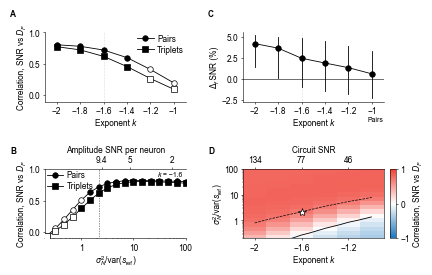

In [7]:
NOISE_SHOW = (0.2, 100.0)


def draw_r_vs_k(ax):  # A
    ks = np.array(K_VALUES)
    ax.axvline(K_REF, color='0.75', lw=0.8, ls=':', zorder=0)
    for m in SIZES:
        rp_k = [correlation(m, k) for k in K_VALUES]
        r = np.array([v[0] for v in rp_k]); p = np.array([v[1] for v in rp_k])
        ax.plot(ks, r, '-', color='k', lw=1.2, zorder=2)
        for x, ri, pi in zip(ks, r, p):
            ax.plot(x, ri, ls='none', marker=MARKER_N[m], markersize=8,
                    markerfacecolor='k' if pi < 0.05 else 'w',
                    markeredgecolor='k', markeredgewidth=1.0, zorder=3)
    k_axis(ax)
    ax.set_ylim(-0.1, 1.0)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_ylabel('Correlation, SNR vs D_F')
    strip_spines(ax)
    ax.legend(handles=[Line2D([], [], ls='-', lw=1.2, color='k', marker=MARKER_N[m],
                              markersize=8, markerfacecolor='k',
                              markeredgecolor='k', markeredgewidth=1.0, label=SIZE_NAME[m])
                       for m in SIZES],
              loc='upper right', frameon=False, handletextpad=0.4, labelspacing=0.25,
              borderpad=0.0, borderaxespad=0.2)


def draw_r_vs_noise(ax, k=K_REF):  # B
    ik = int(np.argmin(np.abs(KM_K - k)))
    sel = (KM_NOISE >= NOISE_SHOW[0]) & (KM_NOISE <= NOISE_SHOW[1])
    ax.axvline(NOISE_AT, color='k', ls=':', lw=0.9, zorder=1)
    for m in SIZES:
        r, pv = KM_R[m][ik, sel], KM_P[m][ik, sel]
        ax.plot(KM_NOISE[sel], r, '-', color='k', lw=1.2, zorder=2)
        for x, ri, pi in zip(KM_NOISE[sel], r, pv):
            ax.plot(x, ri, ls='none', marker=MARKER_N[m], markersize=8,
                    markerfacecolor='k' if pi < 0.05 else 'w',
                    markeredgecolor='k', markeredgewidth=1.0, zorder=3)
    ax.set_xscale('log')
    plain_log_ticks(ax.xaxis)
    ax.set_xlim(*NOISE_SHOW)
    ax.set_ylim(-0.1, 1.0)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xlabel('σ_N^2/var(s_ref)')
    ax.set_ylabel('Correlation, SNR vs D_F')
    strip_spines(ax)
    ax.legend(handles=[Line2D([], [], ls='-', lw=1.2, color='k', marker=MARKER_N[m],
                              markersize=8, markerfacecolor='k',
                              markeredgecolor='k', markeredgewidth=1.0, label=SIZE_NAME[m])
                       for m in SIZES],
              loc='upper left', frameon=False, handletextpad=0.4,
              labelspacing=0.25, borderpad=0.0, borderaxespad=0.2)
    top = ax.secondary_xaxis('top', functions=(amp_at, level_at))
    top.set_xticks([9.4, 5, 2, 1])
    top.set_xticklabels(['9.4', '5', '2', '1'])
    top.set_xlabel('Amplitude SNR per neuron', labelpad=4)
    top.tick_params(which='minor', length=0)
    top.spines['top'].set_visible(True)
    ax.text(0.98, 0.97, f'k = {k_label(k)}', transform=ax.transAxes, ha='right',
            va='top', fontsize=10)


def draw_delta_f(ax):  # C
    ax.axhline(0, color='k', lw=0.8, zorder=1)
    ax.axvline(K_REF, color='0.75', lw=0.8, ls=':', zorder=0)
    ks = np.array(K_VALUES)
    ax.plot(ks, [DELTA_F[k][0] for k in K_VALUES], '-', color='k', lw=1.2, zorder=2)
    for x, k in zip(ks, K_VALUES):
        med, (lo, hi) = DELTA_F[k]
        ax.plot([x, x], [lo, hi], '-', color='k', lw=1.2, zorder=2)
        ax.plot(x, med, 'o', markersize=8, markerfacecolor='k', markeredgecolor='k',
                markeredgewidth=1.0, zorder=3)
    k_axis(ax)
    ax.set_ylabel('Δ_f SNR (%)')
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    strip_spines(ax)


def draw_r_map(ax, cax, m=2):  # D
    X, Y = np.meshgrid(KM_K, KM_NOISE, indexing='ij')
    pm = ax.pcolormesh(X, Y, KM_R[m], cmap=CMAP_R, vmin=-1, vmax=1, shading='nearest',
                       rasterized=True)
    ax.contour(X, Y, KM_R[m], levels=[0.0], colors='k', linewidths=1.2)
    ax.contour(X, Y, KM_R[m], levels=[KM_R[m][k_op, j_op]], colors='k', linewidths=1.0,
               linestyles='--')
    ax.plot(K_REF, NOISE_AT, '*', ms=12, mfc='w', mec='k', mew=1.0, zorder=5)
    ax.set_yscale('log')
    plain_log_ticks(ax.yaxis)
    ax.set_ylim(*NOISE_SHOW)
    ax.set_xticks([-2, -1.6, -1.2])
    ax.set_xticklabels(['−2', '−1.6', '−1.2'])
    ax.set_xlabel('Exponent k')
    ax.set_ylabel('σ_N^2/var(s_ref)')
    top = ax.secondary_xaxis('top')  # mean SNR of the non-redundant circuits at NOISE_REF
    top.set_xticks([-2, -1.6, -1.2])
    top.set_xticklabels([f'{CIRCUIT_SNR[m][k]:.0f}' for k in (-2.0, -1.6, -1.2)])
    top.set_xlabel('Circuit SNR', labelpad=4)
    top.tick_params(which='minor', length=0)
    ax.set_title(SIZE_NAME[m], loc='right', fontsize=10, pad=34)
    cb = plt.colorbar(pm, cax=cax, ticks=[-1, 0, 1])
    cb.set_label('Correlation, SNR vs D_F')


def shrink(Fig, f):
    # scale every size in Fig by f: fonts, lines, markers, ticks, spines, pads, legends
    rc = matplotlib.rcParams
    axes = list(Fig.axes) + [c for ax in Fig.axes for c in ax.child_axes]
    for ax in axes:
        for ln in ax.lines:
            ln.set_linewidth(ln.get_linewidth() * f)
            ln.set_markersize(ln.get_markersize() * f)
            ln.set_markeredgewidth(ln.get_markeredgewidth() * f)
        for co in ax.collections:
            co.set_linewidths(np.asarray(co.get_linewidths()) * f)
            if hasattr(co, 'get_sizes') and len(co.get_sizes()):
                co.set_sizes(np.asarray(co.get_sizes()) * f ** 2)
        for t in ax.texts + [ax.title, ax._left_title, ax._right_title]:
            t.set_fontsize(t.get_fontsize() * f)
        ax._set_title_offset_trans(ax.titleOffsetTrans._t[1] * 72 * f)
        for sp in ax.spines.values():
            sp.set_linewidth(sp.get_linewidth() * f)
        for axis, k in ((ax.xaxis, 'xtick'), (ax.yaxis, 'ytick')):
            axis.label.set_fontsize(axis.label.get_fontsize() * f)
            axis.labelpad *= f
            for which in ('major', 'minor'):
                size = axis._major_tick_kw.get('size', rc[f'{k}.{which}.size']) if which == 'major' \
                    else axis._minor_tick_kw.get('size', rc[f'{k}.{which}.size'])
                axis.set_tick_params(which=which, size=size * f,
                                     width=rc[f'{k}.{which}.width'] * f,
                                     pad=rc[f'{k}.{which}.pad'] * f,
                                     labelsize=rc[f'{k}.labelsize'] * f)
        leg = ax.get_legend()
        if leg is not None:
            hs = leg.legend_handles
            for h in hs:
                h.set_linewidth(h.get_linewidth() * f)
                if isinstance(h, Line2D):
                    h.set_markersize(h.get_markersize() * f)
                    h.set_markeredgewidth(h.get_markeredgewidth() * f)
            ax.legend(handles=hs, labels=[t.get_text() for t in leg.get_texts()], loc=leg._loc,
                      frameon=False, fontsize=leg._fontsize * f, handlelength=leg.handlelength,
                      handletextpad=leg.handletextpad, labelspacing=leg.labelspacing,
                      borderpad=leg.borderpad, borderaxespad=leg.borderaxespad)
    for t in Fig.texts:
        t.set_fontsize(t.get_fontsize() * f)


SHRINK = 0.5  # laid out at full size, then shrunk: 6 pt text
BX = (BOX[0] * SHRINK, BOX[1] * SHRINK)
ML, MB, MR, MT = M_L * SHRINK, M_B * SHRINK, M_R * SHRINK, M_T * SHRINK
GX, GY = ML + 0.35 * SHRINK, MB + MT + 0.55 * SHRINK
W = ML + 2 * BX[0] + GX + MR + 0.95 * SHRINK
H = MB + 2 * BX[1] + GY + MT + 0.55 * SHRINK
x0 = [ML, ML + BX[0] + GX]
y0 = [MB + BX[1] + GY, MB]

Fig = plt.figure(figsize=(W, H))
axA = Fig.add_axes([x0[0] / W, y0[0] / H, BX[0] / W, BX[1] / H])
axC = Fig.add_axes([x0[1] / W, y0[0] / H, BX[0] / W, BX[1] / H])
axB = Fig.add_axes([x0[0] / W, y0[1] / H, BX[0] / W, BX[1] / H])
axD = Fig.add_axes([x0[1] / W, y0[1] / H, BX[0] / W, BX[1] / H])
cax = Fig.add_axes([(x0[1] + BX[0] + 0.12 * SHRINK) / W, y0[1] / H, 0.12 * SHRINK / W, BX[1] / H])
draw_r_vs_k(axA); draw_delta_f(axC); draw_r_vs_noise(axB); draw_r_map(axD, cax)
for ax, letter in ((axA, 'A'), (axC, 'C'), (axB, 'B'), (axD, 'D')):
    bx = ax.get_position()
    Fig.text(bx.x0 - (ML - 0.1 * SHRINK) / W, bx.y1 + 0.28 * SHRINK / H, letter, fontsize=12,
             fontweight='bold', ha='left', va='bottom')
shrink(Fig, SHRINK)
richify(Fig)
Fig.savefig(PATH_PDF / 'FigS3_NoiseExponent.pdf', bbox_inches='tight')
plt.show()